# Lecture 22 - Multi-modal Models

[![View notebook on Github](https://img.shields.io/static/v1.svg?logo=github&label=Repo&message=View%20On%20Github&color=lightgrey)](https://github.com/avakanski/Fall-2026-Applied-Data-Science-with-Python/blob/main/Lectures/Theme_3-Model_Engineering/Lecture_22-Multimodal_Models/Lecture_22-Multimodal_Models.ipynb)
[![Open In Collab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/avakanski/Fall-2026-Applied-Data-Science-with-Python/blob/main/Lectures/Theme_3-Model_Engineering/Lecture_22-Multimodal_Models/Lecture_22-Multimodal_Models.ipynb)
[![View on Website](https://img.shields.io/static/v1.svg?logo=quarto&label=Web&message=View%20on%20Website&color=blue)](https://avakanski.github.io/Fall-2026-Applied-Data-Science-with-Python/Lectures/Theme_3-Model_Engineering/Lecture_22-Multimodal_Models/Lecture_22-Multimodal_Models.html)

<a id='top'></a>

- [22.1 Introduction to Vision-Language Models](#22.1-introduction-to-vision-language-models)
- [22.2 VLM Architectures](#22.2-vlm-architectures)
    - [22.2.1 VLMs with Shared Multi-modal Embeddings](#22.2.1-vlms-with-shared-multi-modal-embeddings)
    - [22.2.2 VLMs with Fused Multi-modal Embeddings](#22.2.2-vlms-with-fused-multi-modal-embeddings)
    - [22.2.3 Modern VLMs](#22.2.3-modern-vlms)
- [22.3 Finetuning Example: Qwen3-VL on Radiology Images](#22.3-finetuning-example-qwen3-vl-on-radiology-images)
- [22.4 Benchmarking VLMs](#22.4-benchmarking-vlms)
- [22.5 Importance of VLMs](#22.5-importance-of-vlms)
- [22.6 VLM Limitations](#22.6-vlm-limitations)
- [22.7 Other Multi-modal Models](#22.7-other-multi-modal-models)
- [References](#references)

This lecture introduces **multi-modal models**, which process and integrate information from more than one data modality, such as text, images, audio, video, and other modalities. We will focus on **Vision-Language Models (VLMs)**, which are currently the most widely used class of multi-modal models. We will cover VLM architectures, followed by an example of finetuning a VLM on a custom dataset of medical images. The lecture concludes with a discussion of the importance and limitations of VLMs, and a brief overview of other types of multi-modal models.

<a id="22.1-introduction-to-vision-language-models"></a>

## 22.1 Introduction to Vision-Language Models

VLMs are multi-modal systems that jointly process and reason over visual information (images, videos) and linguistic information (text). By integrating the two modalities, VLMs learn relationships between visual content and natural language.

Two general families of VLMs are:

- **Embedding-based VLMs** (e.g., CLIP) encode images and text into aligned representations. These models support tasks like similarity scoring, image retrieval, and zero-shot image classification, but do not generate conversational responses.
- **Generative VLMs** (e.g., LLaVA, Qwen-VL) generate text conditioned on visual inputs and a text prompt. These models can describe images, answer questions about them, and have image-grounded conversations.

The following diagram illustrates the generative type of VLMs.

<img src="https://raw.githubusercontent.com/avakanski/Fall-2026-Applied-Data-Science-with-Python/main/Lectures/Theme_3-Model_Engineering/Lecture_22-Multimodal_Models/images/vlm_structure.png" width="450">

*Figure: VLM structure.* Source: [1].

Training data for VLMs can include image-caption pairs, documents with interleaved images and text, visual question-answer pairs, grounding annotations, and video-text examples. Building datasets for VLMs requires collecting a large number of images and corresponding text. Several very large datasets that have been essential for training modern VLMs contain millions or billions of image-text pairs, with descriptions in English and other languages. For instance, the [LAION-5B](https://laion.ai/blog/laion-5b/) dataset has 5.8 billion image-text examples, and the [PMD (Public Multimodal Dataset)](https://huggingface.co/datasets/facebook/pmd) contains 70 million image-text examples. However, dataset scale alone does not guarantee a high-quality VLM, as captions may be noisy or contain information that is not visible in the image.

During training, a VLM learns relationships between visual and textual representations, which allow the model to associate visual features (shapes, colors, spatial relations) with linguistic concepts. The figure below illustrates a VLM performing tasks such as object localization, segmentation, visual question answering, and learning from image-based instructions. The user prompts are shown on the left, and the model responses are shown on the right. As demonstrated in this example, VLMs can interpret not only the semantic content of images, but also spatial relations in images, such as the relative positions of objects. Some VLMs can also output bounding boxes or segmentation masks of objects, although these capabilities require suitable training data and output formats, and are not supported by every VLM.

<img src="https://raw.githubusercontent.com/avakanski/Fall-2026-Applied-Data-Science-with-Python/main/Lectures/Theme_3-Model_Engineering/Lecture_22-Multimodal_Models/images/VLM_capabilities.jpg" width="700">

*Figure: VLM prompts and responses.* Source: [2].

In general, VLMs can perform various multi-modal tasks, including:

- Image and video captioning or summarization: generate context-aware descriptions of images or video frames.
- Visual question answering (VQA): answer open-ended questions based on visual content.
- Image-based reasoning and grounding: provide explanations or logical reasoning about visual scenes, or identify the object referred to in a phrase.
- Text-to-image search: retrieve images, figures, or diagrams in documents that match a textual query.
- Optical Character Recognition (OCR): read text in images, documents, tables, and charts.
- Image generation and editing: generate new images or edit existing images based on textual prompts (in models designed for visual outputs).

<a id="22.2-vlm-architectures"></a>

## 22.2 VLM Architectures

Numerous VLM architectures have been proposed in recent years that employ different strategies to integrate visual and textual information. Two broad categories are VLM architectures with shared multi-modal embeddings and VLM architectures with fused multi-modal embeddings, illustrated in the figure.

<img src="https://raw.githubusercontent.com/avakanski/Fall-2026-Applied-Data-Science-with-Python/main/Lectures/Theme_3-Model_Engineering/Lecture_22-Multimodal_Models/images/vlm_architectures.png" width="550">

*Figure: VLM architectures.* Source: [3].

<a id="22.2.1-vlms-with-shared-multi-modal-embeddings"></a>

### 22.2.1 VLMs with Shared Multi-modal Embeddings

VLMs with shared multi-modal embeddings typically have a dual-encoder architecture (i.e., separate vision and text encoders) that produces aligned embeddings [4].

Input modalities include *visual inputs* (images, PDF documents, or videos) and *textual inputs* (captions, question-answer pairs, or instructions).

**Encoders:** A *vision encoder* converts an image into visual features, and a *text encoder* converts the text (e.g., an image caption) into text features. The vision encoder in VLMs is commonly a variant of the Vision Transformer (ViT), although other designs are also possible. The text encoder is typically a Transformer-based encoder that is pretrained on large text corpora.

Regarding the *vision encoder* part, recall from the section on Vision Transformers in Lecture 19 that a ViT divides the image into patches, embeds each patch, and uses self-attention to allow the patch representations to incorporate information from other parts of the image. Positional information helps the model represent where the features occur. For example, a 224 × 224 image divided into 16 × 16 patches produces 14 × 14 = 196 patch positions.

**Projection and alignment:** The visual and textual features are projected into a shared multi-modal embedding space. This step is achieved through a *projector head* (a.k.a. projector layer, or just projector), which is usually implemented as a linear layer or a small block of fully-connected layers. The two encoders process the image and the text separately, and the projectors align their outputs so that the embeddings of an image and its matching description are close to each other in the shared embedding space.

The shared embedding space enables VLMs to link textual concepts (e.g., the word "cat") with the corresponding visual content (images of cats). For instance, the model represents "cat" not just as a word, but also in terms of how cats appear in images.

One representative model of this type of VLM architecture is CLIP (Contrastive Language-Image Pretraining) [5]. It was one of the first models to introduce large-scale vision-language alignment through contrastive learning. CLIP employs both a vision encoder and a text encoder, and learns a shared embedding space in which images and their textual descriptions are semantically aligned. *Contrastive learning* in CLIP is employed to associate visual and textual content by maximizing the similarity between matched image and text pairs and minimizing the similarity between mismatched pairs. In the figure below, the image encoder outputs image embeddings $I_1, I_2, I_3, ..., I_N$ for the images in the batch, and the text encoder outputs text embeddings $T_1, T_2, T_3, ..., T_N$ for the corresponding texts in the batch. The model computes a similarity score $I_i\cdot T_j$ between each image embedding (e.g., $I_i$) and text embedding (e.g., $T_j$) in the batch. The similarity scores are calculated as the dot product of the image and text embeddings, which equals the cosine similarity because CLIP normalizes the embeddings to unit length. As training progresses, the two encoders are updated so that image and text representations corresponding to similar concepts are drawn close to each other in the shared embedding space, while dissimilar concepts are pushed apart.

<img src="https://raw.githubusercontent.com/avakanski/Fall-2026-Applied-Data-Science-with-Python/main/Lectures/Theme_3-Model_Engineering/Lecture_22-Multimodal_Models/images/CLIP.png" width="450">

*Figure: CLIP architecture.* Source: [6].

A trained CLIP model can perform *zero-shot classification*, where an image is encoded together with candidate text prompts such as "a photo of a cat" and "a photo of a dog", and the prompt with the most similar embedding is selected as the predicted class.

The pretrained vision encoder of CLIP has been widely adopted as the vision encoder component in numerous later VLMs.

<a id="22.2.2-vlms-with-fused-multi-modal-embeddings"></a>

### 22.2.2 VLMs with Fused Multi-modal Embeddings

Generative VLMs commonly employ architectures with fused multi-modal embeddings, which combine a pretrained *vision encoder* with a pretrained *decoder-only language model*. These models fuse image and text representations into joint multi-modal representations, which enables more advanced visual reasoning.

Two important connection patterns in this category of VLMs are:

- **Projected visual tokens:** a projector maps the visual features to the hidden dimension (the size of token embedding vectors) of the language model. The visual tokens are placed alongside the text-token embeddings, and the language model decoder applies self-attention over the combined sequence of visual and text tokens. LLaVA is an example of this pattern.
- **Cross-attention:** the layers of the language model attend to a separate sequence of visual features through cross-attention. Flamingo and Llama 3.2 Vision are examples of this pattern.

**VLMs with Projected Visual Tokens**

The following figure illustrates the workflow of VLMs with projected visual tokens. The visual embeddings from the **vision encoder** are first transformed by the multi-modal **projector** into the embedding space of the LLM. The projector learns a transformation that makes the visual features usable by the LLM. The **LLM decoder** receives a combined input sequence consisting of visual embeddings (image tokens) from the projector and text embeddings (text tokens) from the user's prompt. The LLM decoder serves as the text generation backbone, and using the combined image and text tokens, it generates a textual output in an autoregressive manner, one token at a time. Each new token is conditioned on the previously generated tokens and on the image and text tokens in the input.

The original LLaVA model used a single linear (dense) layer as the projector, and LLaVA-1.5 replaced it with a two-layer network [7, 8].

If a projector maps each feature to an embedding vector with dimension 4,096 (the hidden dimension of the LLM), the resulting sequence of visual tokens has shape 196 × 4,096.

Higher-resolution images can preserve small text and fine details, but they generally produce more visual tokens and increase the memory use and computation. To manage the number of visual tokens, models may resize images, divide them into tiles, merge neighboring features, or use learned resampling. For document analysis or medical images, aggressive resizing can remove exactly the small features that are needed to answer a question.

For instance, Qwen3-VL uses 16 × 16 spatial patches and the feature vectors for each 2 × 2 group of neighboring patches are afterward merged, producing a spatial compression factor of 32. A 512 × 512 image therefore yields approximately (512 / 32)² = 16² = 256 visual tokens [9, 10].

<img src="https://raw.githubusercontent.com/avakanski/Fall-2026-Applied-Data-Science-with-Python/main/Lectures/Theme_3-Model_Engineering/Lecture_22-Multimodal_Models/images/vlm_fused_embeddings.png" width="300">

*Figure: Fused multi-modal VLM with projected visual tokens.* Source: [2].

A common *training strategy* for VLMs with projected visual tokens involves multiple stages, as shown in the next figure. In the first stage, only the multi-modal projector (also referred to as fusion layer, adapter, or connector) is trained, while the image encoder and the LLM text decoder are kept frozen. This is followed by a second, instruction-tuning stage that involves additional finetuning of the multi-modal projector and parts of the LLM text decoder, while the image encoder is kept frozen. Other training strategies also finetune the vision encoder, or add further post-training stages.

<img src="https://raw.githubusercontent.com/avakanski/Fall-2026-Applied-Data-Science-with-Python/main/Lectures/Theme_3-Model_Engineering/Lecture_22-Multimodal_Models/images/vlm_training.png" width="550">

*Figure: VLM training.* Source: [2].

**VLMs with Cross-attention**

Representative models of this class of VLM architectures are Flamingo and Llama 3.2 Vision [11], which use a **cross-attention mechanism** to fuse image and text embeddings [12]. This architecture is shown in the next figure, as well as in the above figure on VLM architectures on the right. The cross-attention mechanism in VLMs is similar to the cross-attention module that connects the encoder and decoder in the standard Transformer network. Instead of adding image tokens to the input sequence as in the projected visual tokens concept, cross-attention layers inserted in the language model allow the text tokens to attend directly to the visual features.

<img src="https://raw.githubusercontent.com/avakanski/Fall-2026-Applied-Data-Science-with-Python/main/Lectures/Theme_3-Model_Engineering/Lecture_22-Multimodal_Models/images/vlm_cross_attention.png" width="250">

*Figure: VLMs with cross-attention.*

<a id="22.2.3-modern-vlms"></a>

### 22.2.3 Modern VLMs

The VLMs discussed above laid the foundations for modern multi-modal models. Among open-weight VLMs, the design with projected visual tokens is currently dominant. Models such as Qwen3-VL, InternVL, Gemma 3, and Pixtral combine a ViT-based vision encoder, an MLP projector, and an LLM decoder. The improvements in these models mostly concern how images are converted into visual tokens (e.g., support for different image resolutions and aspect ratios, and merging of neighboring visual tokens), as well as the scale and quality of the training data. Cross-attention designs have become less common. For instance, Meta used cross-attention in Llama 3.2 Vision [11], but adopted a different design in Llama 4 [13].

**Late fusion and early fusion.** Multi-modal architectures can also be distinguished by the stage at which the modalities are fused, and are categorized as:

- **Late fusion:** the image is first processed by a separate, deep vision encoder, which is typically pretrained on its own (e.g., the vision encoder of CLIP), and the output of the encoder is then fused with the text in the language model. The VLMs with projected visual tokens and with cross-attention that we discussed above are late fusion models.
- **Early fusion:** the image is converted into tokens with minimal processing, and the image and text tokens are processed together by a single Transformer from the first layer. For example, Fuyu has no image encoder, and the image patches are linearly projected into the first layer of the Transformer [14], while Chameleon converts images into discrete image tokens, similar to text tokens, which allows it to both understand and generate images [15].

<img src="https://raw.githubusercontent.com/avakanski/Fall-2026-Applied-Data-Science-with-Python/main/Lectures/Theme_3-Model_Engineering/Lecture_22-Multimodal_Models/images/vlm_fusion.png" width="700">

*Figure: Late-fusion and early-fusion VLM architectures.*

<img src="https://raw.githubusercontent.com/avakanski/Fall-2026-Applied-Data-Science-with-Python/main/Lectures/Theme_3-Model_Engineering/Lecture_22-Multimodal_Models/images/vlm_late_early_fusion.png" width="700">

*Figure: Late-fusion vs early-fusion.*

**Natively multi-modal models.** Developers typically use the term *natively multi-modal* for models that are pretrained jointly on text, images, and often audio and video, from the start of training using early fusion. For instance, Google describes the Gemini models as multi-modal from the ground up, trained jointly across text, image, audio, and video data [16]. OpenAI described GPT-4o as a single model trained end-to-end across text, vision, and audio [17], and Meta describes Llama 4 as natively multi-modal, using early fusion to integrate text and vision tokens into a unified model backbone [13]. The exact architectures of commercial frontier models are not publicly disclosed, and we cannot tell which fusion design they use.

<a id="22.3-finetuning-example-qwen3-vl-on-radiology-images"></a>

## 22.3 Finetuning Example: Qwen3-VL on Radiology Images

This section presents an example of finetuning a VLM on a custom dataset containing medical images, including X-rays, CT scans, and ultrasound images that show various medical conditions and diseases. Each image is paired with a caption from the published article in which the image appeared. The dataset was created by the Unsloth team [18], and it is a smaller sampled version of the ROCO (Radiology Objects in COntext) dataset.

The goal is to adapt a general-purpose VLM, which does not have in-depth knowledge of medical image analysis, to the terminology and style of radiology image descriptions.

By relying on parameter-efficient finetuning techniques, including quantization and LoRA, we will finetune the VLM using a single T4 GPU, which is available in the free version of Google Colab.

#### Install Dependencies

Let's first install the libraries for VLM finetuning, and import the required libraries and modules.

In [1]:
# Note that this line may require to Restart the kernel (Runtime > Restart Session) and run it one more time

!pip install -Uqq transformers accelerate peft datasets bitsandbytes pillow trl

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
import torch
from transformers import (Qwen3VLForConditionalGeneration, AutoProcessor, BitsAndBytesConfig, set_seed)
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from trl import SFTConfig, SFTTrainer
from datasets import load_dataset
import gc
import warnings
warnings.filterwarnings('ignore')

# Set the random seed for reproducibility
set_seed(42)

# PyTorch version
print(f"PyTorch version: {torch.__version__}")

PyTorch version: 2.14.1+cu130


#### Load the VLM

Next, we will load the VLM `Qwen3-VL-4B-Instruct`. The first cell defines the `BitsAndBytesConfig` for loading the model parameters using 4-bit quantization, and afterward, the model and processor for Qwen3-VL are loaded. The processor handles both the text tokenization and the image preprocessing. The parameters of `BitsAndBytesConfig` are explained in Lecture 20.

Note that the T4 GPU does not support the `bfloat16` data format. Therefore, we set `bnb_4bit_compute_dtype=torch.float16` to perform the computations with the quantized weights in the `float16` format. In addition, when loading the model we set `dtype=torch.float32`, so that the model parameters that are not quantized are stored in the `float32` format, since Qwen3-VL models can produce invalid outputs when these parameters are stored in the `float16` format.

In [3]:
# Define bnb_config for loading quantized parameters
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

In [4]:
model_name = "Qwen/Qwen3-VL-4B-Instruct"

# Load model
model = Qwen3VLForConditionalGeneration.from_pretrained(model_name, quantization_config=bnb_config, device_map="auto", dtype=torch.float32)

# Load processor (tokenizer and image preprocessor)
# Qwen3-VL uses 16x16 patches merged 2x2, so each visual token covers 32x32 pixels;
# the image budget is therefore 256 to 512 visual tokens per image
processor = AutoProcessor.from_pretrained(model_name, min_pixels=256*32*32, max_pixels=512*32*32)

config.json:   0%|          | 0.00/1.50k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/64.7k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/269 [00:00<?, ?B/s]

... (3 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

video_preprocessor_config.json:   0%|          | 0.00/385 [00:00<?, ?B/s]

#### Prepare Model for Finetuning

We will use LoRA to finetune the model. The parameters of the LoRA configuration are explained in Lecture 20. As seen from the output below, LoRA finetunes about 0.7% of the 4.5B model parameters.

In [5]:
# Prepare model for quantized training
model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)

# Define LoRA configuration
lora_config = LoraConfig(
    r=16,
    lora_alpha=16,
    target_modules=["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
)

In [6]:
# Apply LoRA to the model
model = get_peft_model(model, lora_config)

# Print the number of trainable parameters
model.print_trainable_parameters()

trainable params: 33,030,144 || all params: 4,470,845,952 || trainable%: 0.7388


#### Load and Format the Dataset

The radiology dataset is loaded next. It consists of 1,978 samples containing images and text. The code in the following cells reformats the dataset for processing with Qwen3-VL, and splits it into training and evaluation subsets. The first 100 samples are held out as an evaluation subset: they are not used for training, and three of them are used to test the model responses before and after finetuning. Formatting prompts for VLMs is slightly more complex than for LLMs, because the user prompts should contain both text and the corresponding images.

In [7]:
# Load the dataset
dataset = load_dataset("unsloth/Radiology_mini", split="train")

README.md:   0%|          | 0.00/610 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  481MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 79.2MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1978 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/327 [00:00<?, ? examples/s]

In [8]:
# Print the number of samples
print(f"Number of samples: {len(dataset)}")

# Print the column names
print(f"Dataset columns: {dataset.column_names}")

Number of samples: 1978
Dataset columns: ['image', 'image_id', 'caption', 'cui']


In [9]:
# Format the radiology dataset to chat format
instructions = ["Describe this medical image in detail.",
    "What are the key findings in this radiology image?",
    "Analyze this medical scan and provide your observations.",
    "What abnormalities or notable features do you see?"]

def format_radiology_sample(sample, idx):

    # Cycle through the instructions, so that the formatting is reproducible
    instruction = instructions[idx % len(instructions)]

    return {"text": f"<|im_start|>user\n<|vision_start|><|image_pad|><|vision_end|>{instruction}<|im_end|>\n<|im_start|>assistant\n{sample['caption']}<|im_end|>",
        "image": sample["image"]}

In [10]:
# Apply formatting to the Dataset
formatted_dataset = dataset.map(
    format_radiology_sample,
    with_indices=True,
    remove_columns=[col for col in dataset.column_names if col != 'image'],
    desc="Formatting dataset",
    num_proc=4,
)

Formatting dataset (num_proc=4):   0%|          | 0/1978 [00:00<?, ? examples/s]

In [11]:
# Split into train and evaluation datasets (the first 100 samples are held out)
eval_size = 100
eval_dataset = formatted_dataset.select(range(eval_size))
train_dataset = formatted_dataset.select(range(eval_size, len(formatted_dataset)))

In [12]:
print(f"Training samples: {len(train_dataset)}")
print(f"Validation samples: {len(eval_dataset)}")
print(f"Columns: {train_dataset.column_names}")

Training samples: 1878
Validation samples: 100
Columns: ['image', 'text']


#### Data Collator

The next cell defines a data collator for Qwen3-VL that combines images and text into batches for processing by the VLM. The collator also creates the labels for training.

Note that the processor expands the single `<|image_pad|>` placeholder in the text into many visual tokens (256 to 512 for our image budget). Therefore, the start of the assistant's response is found by searching the processed input IDs, rather than by tokenizing the prompt text separately.

In [13]:
# Collate text and images into batches for Qwen3VLM
# The code in this cell is not required in preparation for quizzes
class Qwen3VLDataCollator:
    def __init__(self, processor):
        self.processor = processor
        # Token IDs of the assistant header that precedes each response
        self.assistant_ids = processor.tokenizer.encode("<|im_start|>assistant\n", add_special_tokens=False)

    def find_response_start(self, input_ids):
        # Search the processed input IDs, where each image placeholder has already been
        # expanded into many visual tokens, for the assistant header
        n = len(self.assistant_ids)
        for i in range(len(input_ids) - n + 1):
            if input_ids[i:i + n] == self.assistant_ids:
                return i + n
        raise ValueError("Assistant header not found in the sample.")

    def __call__(self, features):
        # Extract text and images
        batch_texts = [f["text"] for f in features]
        batch_images = [f["image"] for f in features]

        # Process
        batch = self.processor(text=batch_texts, images=batch_images, padding=True, truncation=False, return_tensors="pt")

        # Create labels: the loss is calculated only on the assistant's response and its final <|im_end|> token
        labels = batch["input_ids"].clone()
        for idx in range(len(features)):
            start = self.find_response_start(batch["input_ids"][idx].tolist())
            # Mask the user prompt, the image tokens, and the assistant header
            labels[idx, :start] = -100

        # Mask the padding tokens
        labels[batch["attention_mask"] == 0] = -100

        batch["labels"] = labels

        return batch

In [14]:
# Apply the collator class
data_collator = Qwen3VLDataCollator(processor)

# Check the training targets for one sample: only the caption and <|im_end|> should be printed
check_batch = data_collator([train_dataset[0]])
target_ids = check_batch["labels"][0]
print(processor.tokenizer.decode(target_ids[target_ids != -100]))

Intrapleural penetration of the clavicle fracture clearly seen in this coronal section of a computerized tomographic image.<|im_end|>


#### Test the VLM Responses Before Finetuning

Let's check the responses by Qwen3-VL for three images from the held-out evaluation subset before finetuning the model. We use greedy decoding (`do_sample=False`), so that the responses are deterministic, and the responses before and after finetuning can be compared fairly.

Notice in the output below that the model correctly identifies the type of each image (a panoramic dental radiograph, an angiogram, and a chest X-ray) and describes the general anatomy, meaning that Qwen3-VL has been pretrained on medical images by its developers. However, the descriptions are generic rather than focused on the medical findings.

TEST EXAMPLE 0


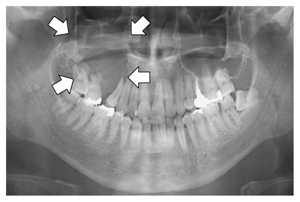

Generated Caption: 
This is a panoramic radiograph (also known as an OPG or orthopantomogram) of the human head and neck, showing both jaws from a posterior-anterior view.

**Overall Appearance:**
- The image displays the full dental arches — upper and lower teeth — along with surrounding bone structure.
- It has high contrast between dense structures like enamel and dentin (appearing white), soft tissues (gray to black), and air-filled spaces (dark).
- There are four large white arrows pointing to specific areas within the oral cavity for emphasis.

---

**Detailed Description by Region:**

1. **Upper Jaw / Maxilla

Ground Truth:
Panoramic radiography shows an osteolytic lesion in the right posterior maxilla with resorption of the floor of the maxillary sinus (arrows).
TEST EXAMPLE 5


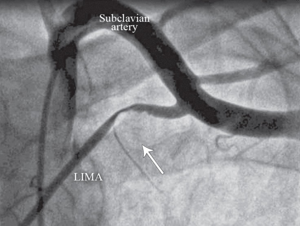

Generated Caption: 
This is a grayscale angiographic image, likely from a cardiac catheterization procedure, showing the vascular anatomy of the upper thorax and mediastinum.

**Key Anatomical Structures:**

1.  **Subclavian Artery:** A large, darkly contrasted vessel running horizontally across the top portion of the image. It's labeled "Subclavian artery" at its origin or proximal course.
2.  **LIMA (Left Internal Mammary Artery):** This is clearly identified by an arrow pointing to it. The LIMA appears as a smaller, well-defined vessel branching off from the subcl

Ground Truth:
Anteroposterior coronary angiographic view of the subclavian artery and left internal mammary artery (LIMA), showing the proximal LIMA compression and severe flow interruption associated with the hyperabduction of left arm (The arrow indicates the area of the compression and the flow interruption.)
TEST EXAMPLE 15


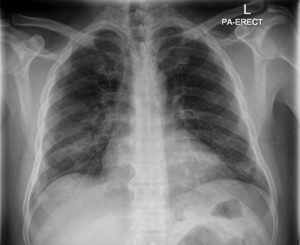

Generated Caption: 
This is a posteroanterior (PA) erect chest radiograph, as indicated by the “L” and “PA-ERECT” markings in the upper right corner — signifying that it was taken with the patient standing upright, facing the X-ray tube from behind.

**Overall Impression:**
The image shows an enlarged cardiac silhouette consistent with cardiomegaly or significant left ventricular hypertrophy. There are also signs of pulmonary congestion and possible interstitial infiltrates bilaterally, which may suggest heart failure or chronic lung disease. The diaphragm appears slightly elevated on both sides but more so on the right side than

Ground Truth:
Frontal chest radiograph displays bilateral scattered lung infiltrates most pronounced in right lower lung zone.


In [15]:
# The code in this cell is not required in preparation for quizzes
instruction = "Describe this medical image in detail."

# Test with 3 samples from the held-out evaluation subset
test_indices = [0, 5, 15]

for idx in test_indices:

    print(f"TEST EXAMPLE {idx}")

    test_image = dataset[idx]["image"]
    ground_truth = dataset[idx]["caption"]

    # Show image
    display_image = test_image.copy()
    display_image.thumbnail((300, 300))
    display(display_image)

    # Format input
    messages = [{"role": "user", "content": [{"type": "image", "image": test_image}, {"type": "text", "text": instruction}]}]

    # Apply chat template
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

    # Process inputs
    inputs = processor(text=[text], images=[test_image], padding=True, return_tensors="pt").to(model.device)

    print("Generated Caption: ")
    with torch.inference_mode():
        # Greedy decoding (do_sample=False) makes the responses before and after finetuning comparable
        output = model.generate(**inputs, max_new_tokens=128, do_sample=False,
            repetition_penalty=1.2, use_cache=True,
            pad_token_id=processor.tokenizer.pad_token_id,
            eos_token_id=processor.tokenizer.eos_token_id)

    # Decode only the newly generated tokens (the assistant's response)
    response = processor.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)

    print(response)
    print("\nGround Truth:")
    print(ground_truth)

#### VLM Finetuning

Similar to Lecture 20, we will use Supervised Finetuning (SFT) with the `SFTTrainer` class from the TRL library to refine the model parameters on the radiology dataset. The training arguments are explained in Lecture 20.

In [16]:
# Training configuration
training_args = SFTConfig(
    output_dir="./qwen3-vlm-4b-radiology",
    # training steps
    max_steps=40,
    # Batch settings
    per_device_train_batch_size=2,
    gradient_accumulation_steps=8,
    gradient_checkpointing=True,
    # Learning rate
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=5,
    # Optimizer
    optim="adamw_torch_fused",
    weight_decay=0.01,
    max_grad_norm=0.3,
    # Precision (the T4 GPU does not support bfloat16)
    bf16=False,
    fp16=False,
    # Logging
    logging_steps=5,
    report_to="none",
    seed=42,
    # Dataset processing
    remove_unused_columns=False,
    dataset_text_field="",
    dataset_kwargs={"skip_prepare_dataset": True})

In [17]:
# Initialize trainer
trainer = SFTTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    data_collator=data_collator,
    processing_class=processor,
    )

Finetuning the model took about 21 minutes on a T4 GPU, where each of the 40 steps used 2 × 8 = 16 samples (a batch size of 2 with 8 gradient accumulation steps), i.e., a total of 40 × 16 = 640 samples out of the 1,878 available samples in the training dataset were used. If you run out of GPU memory, reduce the batch size to 1 and increase the gradient accumulation steps to 16, so that the effective batch size remains 16. Since the T4 GPU does not support the `bfloat16` format, we set `bf16=False` and `fp16=False` in the training configuration, and therefore the LoRA parameters are trained in the `float32` format. Note that setting `fp16=True` results in an error, because the trainable LoRA parameters are stored in the `float32` format.

In [18]:
# Training
trainer.train()

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 151643}.


Step,Training Loss
5,4.157277
10,2.658570
15,2.216754
20,2.332776
25,2.308533
30,2.264600
35,2.260503
40,2.183639


TrainOutput(global_step=40, training_loss=2.5478313684463503, metrics={'train_runtime': 1289.6168, 'train_samples_per_second': 0.496, 'train_steps_per_second': 0.031, 'total_flos': 7469799837517824.0, 'train_loss': 2.5478313684463503, 'epoch': 0.3407880724174654})

In [19]:
# Save the finetuned model
output_dir = "./qwen3-vlm-4b-radiology-final"
trainer.model.save_pretrained(output_dir)
processor.save_pretrained(output_dir)

['./qwen3-vlm-4b-radiology-final/processor_config.json']

#### Perform Inference with the Finetuned Model

Now that the VLM has been finetuned, let's test the model using the same examples from above, and check the generated responses. We will reload the base model and the trained LoRA adapters, and then generate responses for the same images. Note that saving the PEFT model saves only the adapter weights and configuration, so the base model checkpoint is still required.

In [20]:
# Clear the training model from memory
del model
del trainer
gc.collect()
torch.cuda.empty_cache()

In [21]:
from peft import PeftModel

# Reload base model with bnb quantization
base_model = Qwen3VLForConditionalGeneration.from_pretrained("Qwen/Qwen3-VL-4B-Instruct",
    quantization_config=bnb_config,
    device_map="auto",
    dtype=torch.float32)

# Load the trained adapters
inference_model = PeftModel.from_pretrained(base_model, "./qwen3-vlm-4b-radiology-final/")

# Load processor (tokenizer and image preprocessor)
processor = AutoProcessor.from_pretrained("./qwen3-vlm-4b-radiology-final/", min_pixels=256*32*32, max_pixels=512*32*32)

# Set the model to evaluation mode (the semicolon suppresses printing the model architecture)
inference_model.eval();

Loading weights:   0%|          | 0/713 [00:00<?, ?it/s]

TEST EXAMPLE 0


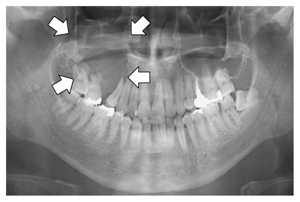

Generated Caption: 
Panoramic radiograph showing the presence of a large cystic lesion (arrows) involving both mandibular and maxillary arches, with marked expansion on buccal aspect of left side of mandible

Ground Truth:
Panoramic radiography shows an osteolytic lesion in the right posterior maxilla with resorption of the floor of the maxillary sinus (arrows).
TEST EXAMPLE 5


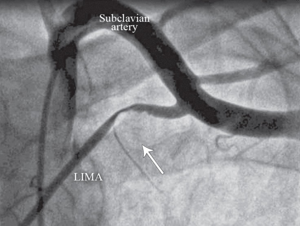

Generated Caption: 
Intraoperative angiography of the left internal mammary artery (LIMA) and subclavian artery showing a 2-cm aneurysmal dilatation at its origin, which was successfully treated with endovascular stenting using a 30-mm × 18 mm balloon-expandable bare-metal stent. The arrow indicates the site of dilation.

Ground Truth:
Anteroposterior coronary angiographic view of the subclavian artery and left internal mammary artery (LIMA), showing the proximal LIMA compression and severe flow interruption associated with the hyperabduction of left arm (The arrow indicates the area of the compression and the flow interruption.)
TEST EXAMPLE 15


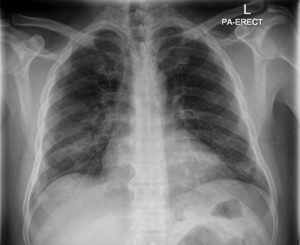

Generated Caption: 
Chest X-ray showing a large right-sided pleural effusion with an associated left lower lobe infiltrate and mediastinal shift to the opposite side (PA view).

Ground Truth:
Frontal chest radiograph displays bilateral scattered lung infiltrates most pronounced in right lower lung zone.


In [22]:
# The code in this cell is not required in preparation for quizzes
instruction = "Describe this medical image in detail."

# Test with the same 3 samples from the held-out evaluation subset
test_indices = [0, 5, 15]

for idx in test_indices:

    print(f"TEST EXAMPLE {idx}")

    test_image = dataset[idx]["image"]
    ground_truth = dataset[idx]["caption"]

    # Show image
    display_image = test_image.copy()
    display_image.thumbnail((300, 300))
    display(display_image)

    # Format input
    messages = [{"role": "user", "content": [{"type": "image", "image": test_image}, {"type": "text", "text": instruction}]}]

    # Apply chat template
    text = processor.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

    # Process inputs
    inputs = processor(text=[text], images=[test_image], padding=True, return_tensors="pt").to(inference_model.device)

    print("Generated Caption: ")
    with torch.inference_mode():
        # Greedy decoding (do_sample=False) makes the responses before and after finetuning comparable
        output = inference_model.generate(**inputs, max_new_tokens=128, do_sample=False,
            repetition_penalty=1.2, use_cache=True,
            pad_token_id=processor.tokenizer.pad_token_id,
            eos_token_id=processor.tokenizer.eos_token_id)

    # Decode only the newly generated tokens (the assistant's response)
    response = processor.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)

    print(response)
    print("\nGround Truth:")
    print(ground_truth)

Note that the responses generated by the finetuned VLM are much shorter than the responses before finetuning, and they follow the concise style and clinical vocabulary of the captions in the finetuning dataset. However, the findings in the responses only partially match the ground truth captions. The responses also contain invented details that cannot be inferred from the images. This is because the captions in the dataset were taken from published case reports, and the model learned to imitate their narrative style. Also, the model was trained only for 40 steps on 640 images, which was insufficient in this case. The hallucinated clinical details illustrate why the outputs of a finetuned VLM must be evaluated on many held-out examples and validated by clinicians before such a model can be used as a tool by medical professionals.

<a id="22.4-benchmarking-vlms"></a>

## 22.4 Benchmarking VLMs

The performance of VLMs is assessed using multi-modal benchmarks that evaluate models on a variety of tasks, such as reasoning, visual question answering, document comprehension, and video understanding. Most benchmarks consist of a set of images with associated questions, often posed as multiple-choice questions. Popular benchmarks include [MMMU](https://mmmu-benchmark.github.io/), [Video-MME](https://video-mme.github.io/home_page.html), [MathVista](https://mathvista.github.io/), and [ChartQA](https://github.com/vis-nlp/ChartQA). MMMU is one of the most comprehensive benchmarks, and contains 11.5K multi-modal questions that require knowledge and reasoning across different disciplines, such as art and engineering.

Several VLM-specific leaderboards provide comparative rankings across diverse metrics. [Vision Arena](https://lmarena.ai/leaderboard/vision) ranks models based on anonymous votes by human users who compare the outputs of two models. The [Open VLM Leaderboard](https://huggingface.co/spaces/opencompass/open_vlm_leaderboard) ranks VLMs according to their scores on different benchmarks and their average scores.

<a id="22.5-importance-of-vlms"></a>

## 22.5 Importance of VLMs

Traditional computer vision models are constrained to learning from a predefined and fixed set of categories or objects for image classification or object detection (e.g., identifying whether an image contains a cat or a dog). Moreover, these tasks require users to manually label a large number of images with a specific category for classification, or to draw bounding boxes around multiple objects in each image for object detection, which is a tedious, time-consuming, and expensive process.

Conversely, VLMs are trained with more detailed textual descriptions of images, where, for example, an image can contain cats, dogs, and other objects, and the text description can provide additional contextual information (e.g., the cat is sitting, the dog is running, etc.). Learning from rich natural language descriptions allows VLMs to better understand visual scenes, without limiting the learning to a narrow set of visual concepts comprising a fixed number of classes and objects. It also greatly reduces the need for manual image labeling, and extends the utility of VLMs beyond traditional CV tasks like classification or detection to new capabilities, including reasoning, summarization, question answering, and interactive dialogue, by simply changing the text prompt.

VLMs have been applied across many domains and industries, and offer great potential to enhance visual perception [19]. For instance, they can be used to review videos and extract insights for industrial inspection and robotics (detect faults, monitor operations, identify anomalies), safety and infrastructure monitoring (recognize floods, fires, or traffic hazards), retail and logistics (track empty shelves, detect misplaced items, identify supply-chain bottlenecks), and numerous other tasks.

<a id="22.6-vlm-limitations"></a>

## 22.6 VLM Limitations

VLM responses can sound confident even when the visual evidence is weak. Important limitations of VLMs include:

- *Hallucinations:* inventing objects, findings, or contextual details that are not supported by the input.
- *Language shortcuts:* answering based on plausible textual associations instead of the actual image.
- *Fine-detail errors:* missing small text, subtle findings, or features that were removed by resizing.
- *Counting and spatial errors:* confusing object counts, positions, relationships, or orientation.
- *Temporal errors:* missing a short event or incorrectly ordering events in sampled video frames.
- *Domain shift:* failing on image types, devices, or settings that differ from the training data.

<a id="22.7-other-multi-modal-models"></a>

## 22.7 Other Multi-modal Models

**Video-language models** sample frames from a video and encode them into visual tokens. Frame order, timestamps, and temporal positional information help represent events over time. Sampling more frames can capture brief events but increases the number of input tokens, whereas sparse sampling can miss such events. For example, Qwen3-VL supports video inputs and explicit timestamp-based temporal alignment [9, 10].

**Audio-capable models** can encode speech or other sounds and produce text, speech, or both. Direct audio processing can preserve cues such as speaker identity, emotion, and intonation that are lost when only a transcript is supplied. Qwen3-Omni is an example of a model that processes text, images, audio, and video, and generates text and speech [20].

**Generative models** for visual generation and editing can create or edit images and videos. Visual generation often relies on diffusion or flow-matching components, rather than only on a text decoder. Some systems, such as UniVideo, combine visual understanding, generation, and editing in a single model [21].

**Visual AI agents** can interpret screenshots and supply actions to a tool that operates a user interface. **Vision-language-action (VLA) models** extend this idea to physical actions. For instance, in robotics, such systems can use a camera to capture images of the environment, a VLM to interpret the images and propose actions, and an action module to control the robot's movements while executing the actions.

## References

1. Vision-language models (VLMs) Explained (pt. 1), by Sean Trott, available at [https://seantrott.substack.com/p/vision-language-models-vlms-explained](https://seantrott.substack.com/p/vision-language-models-vlms-explained).
2. Vision Language Models Explained, Hugging Face Blog, by Merve Noyan and Edward Beeching, available at [https://huggingface.co/blog/vlms](https://huggingface.co/blog/vlms).
3. Vision Language Models (VLMs) Explained, by GeeksforGeeks, available at [https://www.geeksforgeeks.org/artificial-intelligence/vision-language-models-vlms-explained/](https://www.geeksforgeeks.org/artificial-intelligence/vision-language-models-vlms-explained/).
4. Understanding Vision-Language Models (VLMs): A Practical Guide, by Pietro Bolcato, available at [https://medium.com/@pietrobolcato/understanding-vision-language-models-vlms-a-practical-guide-8da18e9f0e0c](https://medium.com/@pietrobolcato/understanding-vision-language-models-vlms-a-practical-guide-8da18e9f0e0c).
5. Learning Transferable Visual Models From Natural Language Supervision (CLIP), by Alec Radford et al., available at [https://arxiv.org/abs/2103.00020](https://arxiv.org/abs/2103.00020).
6. CLIP: Connecting text and images, by OpenAI, available at [https://openai.com/index/clip/](https://openai.com/index/clip/).
7. Visual Instruction Tuning (LLaVA), by Haotian Liu et al., available at [https://arxiv.org/abs/2304.08485](https://arxiv.org/abs/2304.08485).
8. Improved Baselines with Visual Instruction Tuning (LLaVA-1.5), by Haotian Liu et al., available at [https://arxiv.org/abs/2310.03744](https://arxiv.org/abs/2310.03744).
9. Qwen3-VL Technical Report, by Shuai Bai et al., available at [https://arxiv.org/abs/2511.21631](https://arxiv.org/abs/2511.21631).
10. Qwen3-VL GitHub Repository (inference, resolution controls, and video examples), by the Qwen Team, available at [https://github.com/QwenLM/Qwen3-VL](https://github.com/QwenLM/Qwen3-VL).
11. Llama 3.2 Model Cards and Prompt Formats, by Meta, available at [https://dev.meta.ai/llama/docs/model-cards-and-prompt-formats/llama3_2](https://dev.meta.ai/llama/docs/model-cards-and-prompt-formats/llama3_2).
12. Vision Language Models, by Rohit Bandaru, available at [https://rohitbandaru.github.io/blog/Vision-Language-Models/](https://rohitbandaru.github.io/blog/Vision-Language-Models/).
13. The Llama 4 Herd: The Beginning of a New Era of Natively Multimodal AI Innovation, by Meta, available at [https://ai.meta.com/blog/llama-4-multimodal-intelligence/](https://ai.meta.com/blog/llama-4-multimodal-intelligence/).
14. Fuyu-8B Model Card, by Adept AI, available at [https://huggingface.co/adept/fuyu-8b](https://huggingface.co/adept/fuyu-8b).
15. Chameleon: Mixed-Modal Early-Fusion Foundation Models, by the Chameleon Team (Meta), available at [https://arxiv.org/abs/2405.09818](https://arxiv.org/abs/2405.09818).
16. Gemini: A Family of Highly Capable Multimodal Models, by the Gemini Team (Google), available at [https://arxiv.org/abs/2312.11805](https://arxiv.org/abs/2312.11805).
17. Hello GPT-4o, by OpenAI, available at [https://openai.com/index/hello-gpt-4o/](https://openai.com/index/hello-gpt-4o/).
18. Vision Fine-tuning, by Unsloth, available at [https://docs.unsloth.ai/basics/vision-fine-tuning](https://docs.unsloth.ai/basics/vision-fine-tuning).
19. What Are Vision Language Models, by NVIDIA, available at [https://www.nvidia.com/en-us/glossary/vision-language-models/](https://www.nvidia.com/en-us/glossary/vision-language-models/).
20. Qwen3-Omni Technical Report, by Jin Xu et al., available at [https://arxiv.org/abs/2509.17765](https://arxiv.org/abs/2509.17765).
21. UniVideo: Unified Understanding, Generation, and Editing for Videos, by Cong Wei et al., ICLR 2026, available at [https://proceedings.iclr.cc/paper_files/paper/2026/hash/b940430f7acd23302bbaf0680f458e61-Abstract-Conference.html](https://proceedings.iclr.cc/paper_files/paper/2026/hash/b940430f7acd23302bbaf0680f458e61-Abstract-Conference.html).

[BACK TO TOP](#top)